# Naive Bayes on the Wine Dataset — With Cross-Validation and GridSearchCV

**Dataset:** Wine dataset, built into scikit-learn (no CSV download required)  
**Algorithm:** Gaussian Naive Bayes (`GaussianNB`)  
**Goal:** Predict the wine class using 13 chemical measurements.

In this notebook, we will:
1. Load the dataset and split it into training and testing sets.
2. Train a **baseline** Naive Bayes model.
3. Use **5-fold cross-validation** to estimate its performance.
4. Use **GridSearchCV** to tune `var_smoothing`.
5. Evaluate the selected model on the **held-out test set**.
6. Plot the confusion matrix and predict one record.

The code is intentionally simple for classroom use.

## 1. Import libraries

`cross_val_score` runs cross-validation; `GridSearchCV` tries different hyperparameter values and finds the best setting according to cross-validation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Load the Wine dataset

The Wine dataset has **178 records**, **13 numeric features**, and **3 wine classes**. We will use the features as `X` and the class labels as `y`.

In [2]:
wine = load_wine(as_frame=True)

X = wine.data

y = wine.target

print("Dataset shape:", X.shape)
print("Classes:", wine.target_names)
X.head()

Dataset shape: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Check the number of records in each class

In [3]:
print(y.value_counts().sort_index())

target
0    59
1    71
2    48
Name: count, dtype: int64


## 4. Split the dataset into training and testing sets

- **80% training:** used to train the model and run cross-validation / GridSearchCV.
- **20% testing:** reserved for the final evaluation.
- `stratify=y` helps preserve similar class proportions in both sets.

**Important:** We must not use the test set while choosing hyperparameters.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 142
Testing records: 36


## 5. Train a baseline Naive Bayes model

`GaussianNB()` models each numeric feature using a Gaussian (normal) distribution within each class. It assumes the features are conditionally independent given the class.

In [5]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Baseline model trained")

Baseline model trained


## 6. Cross-validation on the training data

**What is 5-fold cross-validation?** We divide the *training data* into 5 folds. We train on 4 folds and validate on the remaining fold. Repeat 5 times so each fold is used for validation once.

`cross_val_score` automatically trains a **fresh model for each fold**. We report the accuracy for every fold and the average accuracy.

In [6]:
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Accuracy in each fold:", cv_scores.round(3))
print("Mean CV accuracy:", round(cv_scores.mean(), 3))
print("CV standard deviation:", round(cv_scores.std(), 3))

Accuracy in each fold: [1.    0.931 1.    0.929 1.   ]
Mean CV accuracy: 0.972
CV standard deviation: 0.034


## 7. Tune Naive Bayes using GridSearchCV

`GaussianNB` has a hyperparameter called **`var_smoothing`**. It adds a small value to the estimated feature variances for numerical stability.

`GridSearchCV` will:
1. Try each value listed in `param_grid`.
2. Use 5-fold cross-validation **on the training set** for each value.
3. Pick the value with the highest mean validation accuracy.
4. Retrain the best model using the entire training set (`refit=True`, the default).

**Note:** Naive Bayes has fewer hyperparameters than decision trees or random forests. Here we tune only `var_smoothing`.

In [7]:
param_grid = {
    "var_smoothing": [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4, 1e-2]
}

grid = GridSearchCV(
    GaussianNB(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best mean CV accuracy:", round(grid.best_score_, 3))

Best parameters: {'var_smoothing': 1e-12}
Best mean CV accuracy: 0.972


## 8. See the GridSearchCV results

Each row is one value of `var_smoothing`, along with its mean accuracy over the 5 validation folds. The `rank_test_score` column ranks the configurations; rank 1 is best.

In [8]:
grid_results = pd.DataFrame({
    "var_smoothing": grid.cv_results_["param_var_smoothing"],
    "mean_cv_accuracy": grid.cv_results_["mean_test_score"],
    "rank": grid.cv_results_["rank_test_score"]
})

grid_results.sort_values("rank")

,var_smoothing,mean_cv_accuracy,rank
0,1.000000e-12,0.971921,1
1,1.000000e-10,0.971921,1
2,1.000000e-09,0.971921,1
3,1.000000e-08,0.971921,1
4,1.000000e-06,0.971921,1
5,1.000000e-04,0.915764,6
6,1.000000e-02,0.719212,7


## 9. Compare baseline CV and tuned CV performance

Compare **validation accuracy**, not test accuracy, when deciding which hyperparameter setting to use. A tuned model is not guaranteed to score higher than the baseline on every dataset.

In [9]:
print("Baseline mean CV accuracy:", round(cv_scores.mean(), 3))
print("Best GridSearchCV accuracy:", round(grid.best_score_, 3))

best_model = grid.best_estimator_
print("Selected model:", best_model)

Baseline mean CV accuracy: 0.972
Best GridSearchCV accuracy: 0.972
Selected model: GaussianNB(var_smoothing=1e-12)


## 10. Make predictions on the test set

Now that tuning is complete, we use the held-out test set **for the first time** to measure final performance.

In [10]:
y_pred = best_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
results.head(10)

,Actual,Predicted
0,0,0
1,2,2
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,1,0
8,1,1
9,2,2


## 11. Evaluate the tuned model

- **Accuracy:** Fraction of correct predictions.
- **Precision:** Among records predicted as a class, how many actually belong to it?
- **Recall:** Among records belonging to a class, how many did the model find?
- **F1-score:** A measure combining precision and recall.

In [11]:
accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(accuracy, 3))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Test accuracy: 0.972

Classification report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## 12. Plot the confusion matrix

- **Rows:** actual classes.
- **Columns:** predicted classes.
- **Diagonal:** correct classifications.
- **Off-diagonal:** mistakes.

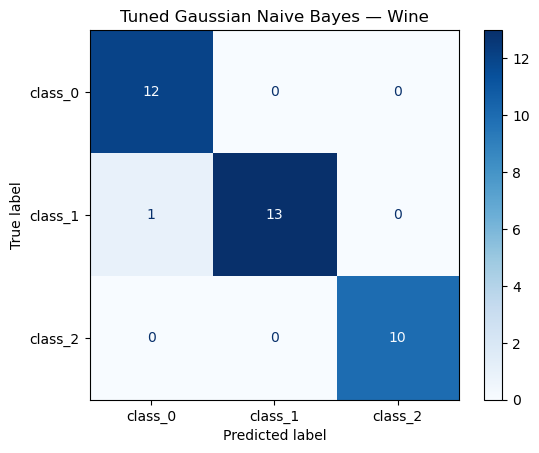

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=wine.target_names,
    cmap="Blues"
)
plt.title("Tuned Gaussian Naive Bayes — Wine")
plt.show()

## 13. Predict one test record

Use `.iloc[[0]]` (double brackets) to keep the selected record as a two-dimensional table containing one row.

In [13]:
one_record = X_test.iloc[[0]]

predicted_class = best_model.predict(one_record)[0]
actual_class = y_test.iloc[0]

print("Actual class:", wine.target_names[actual_class])
print("Predicted class:", wine.target_names[predicted_class])

Actual class: class_0
Predicted class: class_0


## 14. View predicted class probabilities

`predict_proba()` returns a probability estimate for each class. The model selects the class with the highest estimated probability.

In [14]:
probabilities = best_model.predict_proba(one_record)
pd.DataFrame(probabilities, columns=wine.target_names).round(3)

,class_0,class_1,class_2
0,1.0,0.0,0.0


## Key points to remember

1. **GaussianNB:** a simple probability-based classifier for numeric features.
2. **Train/test split:** the test set must remain separate during tuning.
3. **Cross-validation:** estimates model performance by repeatedly changing the validation fold.
4. **GridSearchCV:** checks multiple values of `var_smoothing` using cross-validation.
5. **`grid.best_params_`:** the winning hyperparameter setting.
6. **`grid.best_score_`:** mean cross-validation accuracy of that setting — **not** test accuracy.
7. **`grid.best_estimator_`:** the trained model selected by GridSearchCV.
8. **Final test accuracy:** performance measured once on the held-out test set.

### Classroom questions

- Why do we run cross-validation on `X_train` instead of the full dataset?
- What does `cv=5` mean?
- Why can `grid.best_score_` differ from test accuracy?
- Will GridSearchCV always improve the test accuracy? Why or why not?
- What does `var_smoothing` control?